# ⚙️ Saudi Arabia NWP: Physics-Informed Feature Engineering Pipeline
### *Multi-Station Dust Transport Dynamics, Optical Ratios & Lagged Memory*
**Input:** `notebooks/data/sandstorm_final_dataset_with_targets.csv`  
**Outputs:**  
- `data/processed/saudi_nwp_engineered_features.parquet` (Complete feature store)  
- `data/processed/saudi_nwp_engineered_features.csv` (Verification sample)


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

data_candidates = [
    Path("notebooks/data/sandstorm_final_dataset_with_targets.csv"),
    Path("data/sandstorm_final_dataset_with_targets.csv"),
    Path("../data/sandstorm_final_dataset_with_targets.csv")
]
data_path = next(p for p in data_candidates if p.exists())

df_raw = pd.read_csv(data_path)
df_raw['time'] = pd.to_datetime(df_raw['time'])
df_raw = df_raw.sort_values('time').reset_index(drop=True)

print(f"✅ Ingested Raw Dataset: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")


✅ Ingested Raw Dataset: 37,200 rows × 41 columns


---
## 1.0 Spatial Dust Transport Gradients & Desert Basin Differentials
Sandstorms in central Saudi Arabia are driven by regional pressure and dust concentration gradients between the upstream desert basins and receptor cities. We compute regional emission differentials:
$$\Delta PM_{10}^{	ext{source-receptor}} = PM_{10}^{	ext{desert}} - PM_{10}^{	ext{Riyadh}}$$


In [2]:
df_feats = df_raw.copy()

# 1. Spatial Dust Concentration Gradients towards Riyadh
df_feats['gradient_dahna_riyadh'] = df_feats['ad_dahna__cams_pm10_ugm3'] - df_feats['riyadh_center__cams_pm10_ugm3']
df_feats['gradient_nafud_riyadh'] = df_feats['nafud_al_thuwairat__cams_pm10_ugm3'] - df_feats['riyadh_center__cams_pm10_ugm3']
df_feats['gradient_rub_alkhali_riyadh'] = df_feats['rub_al_khali__cams_pm10_ugm3'] - df_feats['riyadh_center__cams_pm10_ugm3']

# 2. Regional Desert Dust Pool Aggregations (Source Basins)
source_pm10_cols = [
    'ad_dahna__cams_pm10_ugm3',
    'nafud_al_thuwairat__cams_pm10_ugm3',
    'rub_al_khali__cams_pm10_ugm3'
]
source_aod_cols = [
    'ad_dahna__cams_dust_aod_550nm',
    'nafud_al_thuwairat__cams_dust_aod_550nm',
    'rub_al_khali__cams_dust_aod_550nm'
]

df_feats['desert_sources_mean_pm10'] = df_feats[source_pm10_cols].mean(axis=1)
df_feats['desert_sources_max_pm10']  = df_feats[source_pm10_cols].max(axis=1)
df_feats['desert_sources_std_pm10']  = df_feats[source_pm10_cols].std(axis=1)
df_feats['desert_sources_mean_aod']  = df_feats[source_aod_cols].mean(axis=1)

print("✅ Spatial transport gradients & desert basin aggregations engineered!")
df_feats[['gradient_dahna_riyadh', 'gradient_rub_alkhali_riyadh', 'desert_sources_mean_pm10', 'desert_sources_mean_aod']].describe().round(2)


✅ Spatial transport gradients & desert basin aggregations engineered!


,gradient_dahna_riyadh,gradient_rub_alkhali_riyadh,desert_sources_mean_pm10,desert_sources_mean_aod
count,37148.00,37148.00,37200.00,37200.00
mean,-476.39,-577.20,157.32,0.40
std,707.61,767.25,106.19,0.15
min,-3186.40,-3247.30,0.77,0.03
25%,-795.65,-905.72,80.73,0.30
50%,-92.20,-191.85,127.33,0.39
75%,-7.40,-41.00,206.28,0.49
max,1063.60,1790.60,1034.10,1.21


---
## 2.0 Optical Column-to-Surface Ratios & Microphysical Particle Fractions
The vertical distribution and particulate size fraction of atmospheric dust are captured via:



In [3]:
# Optical & Particle Size Fractions
for prefix in ['riyadh_center', 'rub_al_khali', 'ad_dahna']:
    pm10 = df_feats[f"{prefix}__cams_pm10_ugm3"]
    pm25 = df_feats[f"{prefix}__cams_pm2_5_ugm3"]
    aod  = df_feats[f"{prefix}__cams_dust_aod_550nm"]
    
    # Surface-to-column ratio
    df_feats[f"{prefix}__surface_to_column_ratio"] = pm10 / (aod + 1e-4)
    # PM2.5 / PM10 ratio
    df_feats[f"{prefix}__pm25_to_pm10_ratio"] = pm25 / (pm10 + 1e-4)
    # Log transforms for stability in regression models
    df_feats[f"{prefix}__log_pm10"] = np.log1p(pm10)
    df_feats[f"{prefix}__log_aod"]  = np.log1p(aod)

print("✅ Optical column-to-surface & microphysical features engineered!")
df_feats[['riyadh_center__surface_to_column_ratio', 'riyadh_center__pm25_to_pm10_ratio', 'riyadh_center__log_pm10']].head()


✅ Optical column-to-surface & microphysical features engineered!


,riyadh_center__surface_to_column_ratio,riyadh_center__pm25_to_pm10_ratio,riyadh_center__log_pm10
0,115.428312,0.440944,3.947390
1,114.519427,0.444444,3.939638
2,109.753388,0.459513,3.919991
3,108.019996,0.476860,3.925926
4,114.443735,0.475836,4.003690


---
## 3.0 Multi-Scale Temporal Memory: Lags & Rolling Statistics
Dust transport is characterized by memory effects and advective delays. We compute lagged states (1h, 6h, 12h, 24h) and multi-hour rolling statistical moments (6h, 24h, 72h).


In [4]:
key_stations = ['riyadh_center', 'rub_al_khali', 'ad_dahna']

for prefix in key_stations:
    pm10_col = f"{prefix}__cams_pm10_ugm3"
    
    # 1. Lags
    df_feats[f"{prefix}__pm10_lag1h"]  = df_feats[pm10_col].shift(1).bfill()
    df_feats[f"{prefix}__pm10_lag6h"]  = df_feats[pm10_col].shift(6).bfill()
    df_feats[f"{prefix}__pm10_lag12h"] = df_feats[pm10_col].shift(12).bfill()
    df_feats[f"{prefix}__pm10_lag24h"] = df_feats[pm10_col].shift(24).bfill()
    
    # 2. Rolling Statistics (Past 6h, 24h, 72h)
    df_feats[f"{prefix}__pm10_roll6h_mean"]  = df_feats[pm10_col].rolling(6, min_periods=1).mean()
    df_feats[f"{prefix}__pm10_roll24h_mean"] = df_feats[pm10_col].rolling(24, min_periods=1).mean()
    df_feats[f"{prefix}__pm10_roll24h_std"]  = df_feats[pm10_col].rolling(24, min_periods=1).std().fillna(0)
    df_feats[f"{prefix}__pm10_roll72h_max"]  = df_feats[pm10_col].rolling(72, min_periods=1).max()
    
    # 3. Rate of Change (Velocity of dust build-up)
    df_feats[f"{prefix}__pm10_diff1h"]  = df_feats[pm10_col] - df_feats[f"{prefix}__pm10_lag1h"]
    df_feats[f"{prefix}__pm10_diff6h"]  = df_feats[pm10_col] - df_feats[f"{prefix}__pm10_lag6h"]
    df_feats[f"{prefix}__pm10_diff24h"] = df_feats[pm10_col] - df_feats[f"{prefix}__pm10_lag24h"]

print("✅ Multi-scale temporal memory, lags, and rolling features created!")


✅ Multi-scale temporal memory, lags, and rolling features created!


---
## 4.0 Cyclic Atmospheric Solar & Calendar Encodings
We encode periodic seasonal and diurnal cycles using sine/cosine harmonics:



In [5]:
# Temporal calendar features
doy = df_feats['time'].dt.dayofyear
hour = df_feats['hour']
month = df_feats['month']

df_feats['hour_sin']  = np.sin(2 * np.pi * hour / 24.0)
df_feats['hour_cos']  = np.cos(2 * np.pi * hour / 24.0)
df_feats['month_sin'] = np.sin(2 * np.pi * month / 12.0)
df_feats['month_cos'] = np.cos(2 * np.pi * month / 12.0)
df_feats['doy_sin']   = np.sin(2 * np.pi * doy / 365.25)
df_feats['doy_cos']   = np.cos(2 * np.pi * doy / 365.25)

print("✅ Cyclic calendar and solar encodings engineered successfully!")


✅ Cyclic calendar and solar encodings engineered successfully!


---
## 5.0 Feature Correlation Matrix with Predictive Targets
We compute the Pearson correlation matrix of the engineered features against the operational targets.


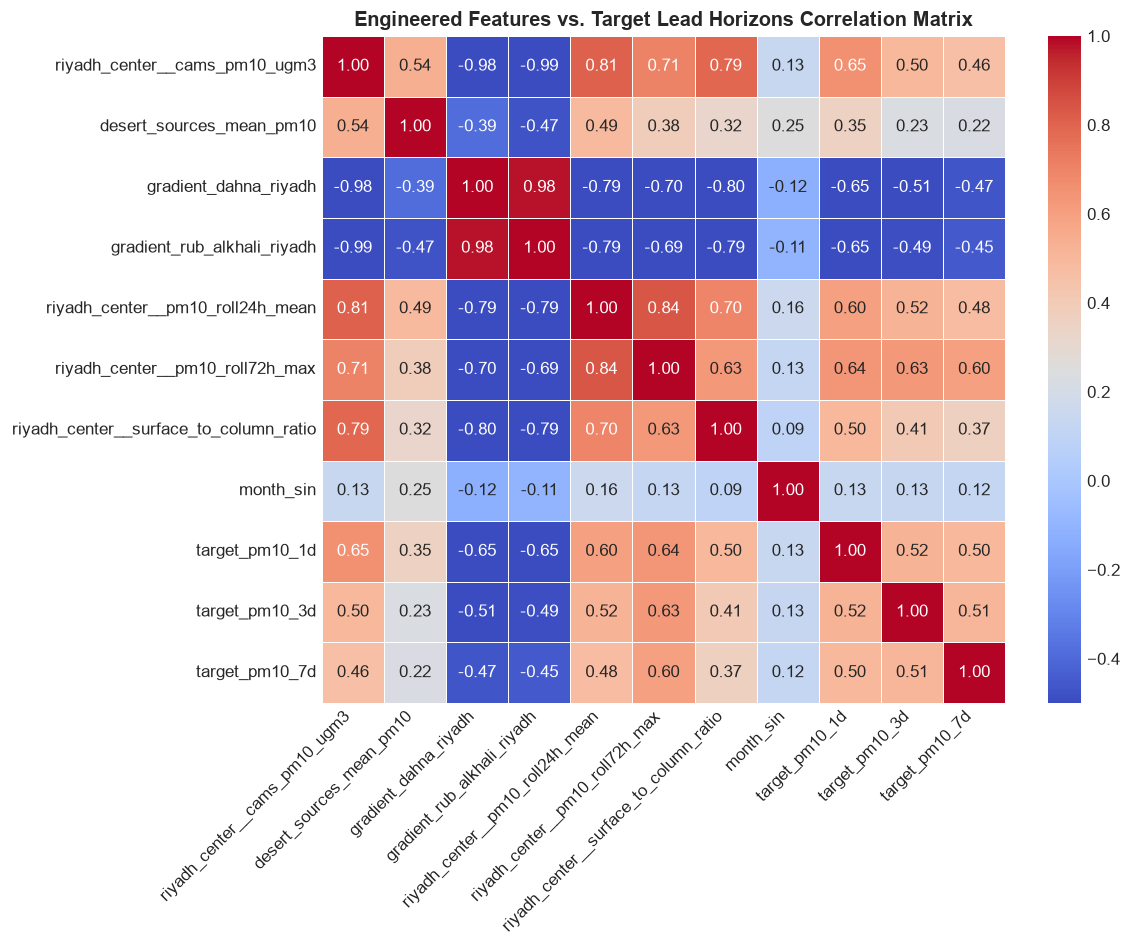

In [6]:
top_feature_cols = [
    'riyadh_center__cams_pm10_ugm3',
    'desert_sources_mean_pm10',
    'gradient_dahna_riyadh',
    'gradient_rub_alkhali_riyadh',
    'riyadh_center__pm10_roll24h_mean',
    'riyadh_center__pm10_roll72h_max',
    'riyadh_center__surface_to_column_ratio',
    'month_sin',
    'target_pm10_1d',
    'target_pm10_3d',
    'target_pm10_7d'
]

clean_corr = df_feats[top_feature_cols].dropna().corr()

plt.figure(figsize=(10, 8))
sns.heatmap(clean_corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.5, vmax=1.0, linewidths=0.5)
plt.title("Engineered Features vs. Target Lead Horizons Correlation Matrix", fontweight="bold")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


---
## 6.0 Feature Pipeline Serialization
We export the engineered feature dataset to Parquet and CSV for consumption by Line A Machine Learning models.


In [7]:
# Export to multiple standard path locations for robust notebook discovery
out_dirs = [
    Path("data/processed"),
    Path("../data/processed"),
    Path("notebooks/data")
]
for d in out_dirs:
    d.mkdir(parents=True, exist_ok=True)

# Primary storage: data/processed/saudi_nwp_engineered_features.parquet
primary_parquet = Path("data/processed/saudi_nwp_engineered_features.parquet")
primary_csv = Path("data/processed/saudi_nwp_engineered_features.csv")

# Forward fill small missing values in sensors if any
df_feats = df_feats.ffill().bfill()

df_feats.to_parquet(primary_parquet, index=False)
df_feats.to_csv(primary_csv, index=False)

# Mirror to notebooks/data/ for direct local access
df_feats.to_parquet(Path("notebooks/data/saudi_nwp_engineered_features.parquet"), index=False)

print("=" * 75)
print("🎉 FEATURE ENGINEERING PIPELINE COMPLETE & SERIALIZED!")
print("=" * 75)
print(f"Total Rows:            {df_feats.shape[0]:,}")
print(f"Total Features:        {df_feats.shape[1]}")
print(f"Engineered Parquet:    {primary_parquet} ({primary_parquet.stat().st_size / 1e6:.2f} MB)")
print(f"Engineered CSV:        {primary_csv} ({primary_csv.stat().st_size / 1e6:.2f} MB)")
print("=" * 75)


🎉 FEATURE ENGINEERING PIPELINE COMPLETE & SERIALIZED!
Total Rows:            37,200
Total Features:        99
Engineered Parquet:    data\processed\saudi_nwp_engineered_features.parquet (9.38 MB)
Engineered CSV:        data\processed\saudi_nwp_engineered_features.csv (38.20 MB)
